# Conectarse a MySQL desde Python
**Taller de Programación para el Análisis de Datos**

En esta notebook vamos a:
1. Instalar el conector oficial de MySQL para Python.
2. Conectarnos al servidor MySQL local.
3. Ejecutar consultas `SELECT` sobre la base de ejemplo **world** y recorrer los resultados.
4. Usar consultas con parámetros (la forma segura).
5. Traer resultados a un DataFrame de **pandas** y graficarlos.

**Antes de empezar:** el servidor MySQL tiene que estar corriendo (servicio `MySQL84` iniciado) y la base `world` instalada.

## 1. Instalación de librerías
- `mysql-connector-python`: conector oficial de Oracle para MySQL.
- `sqlalchemy`: capa que usa pandas para hablar con bases de datos.
- `pandas` y `matplotlib`: para analizar y graficar.

Se ejecuta una sola vez.

<style>
    .yellow {
        background-color: #999900;
    }
</style>

In [1]:
%pip install mysql-connector-python sqlalchemy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. Datos de conexión
Son los mismos que usamos en Workbench. La contraseña se pide con `getpass` para **no dejarla escrita en la notebook** (si la compartís, la contraseña viajaría con ella).

In [2]:
from getpass import getpass

HOST = "db_test"   # o "localhost": el servidor está en nuestra propia computadora
PORT = 3306          # puerto por defecto de MySQL
USER = "taller"
DATABASE = "taller_db"

PASSWORD = getpass("Contraseña de MySQL: ") #DB_PASSWORD=prog

## 3. Crear nuestra base de datos de trabajo

In [3]:
#Crear la Base de datos de prueba y la tabla de ejemplo
import subprocess

try:
    
    backup_dbname = "./world-db/world.sql"
    
    restore_command = f"mysql --host={HOST} --port={PORT} --user={USER} --password={PASSWORD} < {backup_dbname}"

    # Execute the mysql command
    subprocess.run(restore_command, shell=True)

except Exception as err:
    print(f"Error al crear la base de datos: {err}")
    db_

ERROR 2026 (HY000): TLS/SSL error: self-signed certificate in certificate chain


## 4. Conectarse
`mysql.connector.connect()` abre la conexión. Si algo falla (servidor apagado, contraseña incorrecta, base inexistente) se lanza un error que capturamos para mostrar un mensaje claro.

In [4]:
import mysql.connector
from mysql.connector import errorcode

try:
    conn = mysql.connector.connect(
        host=HOST, port=PORT, user=USER, password=PASSWORD, database=DATABASE
    )
    print("Conectado a MySQL", conn.server_info)
except mysql.connector.Error as err:
    if err.errno == errorcode.ER_ACCESS_DENIED_ERROR:
        print("Usuario o contraseña incorrectos")
    elif err.errno == errorcode.ER_BAD_DB_ERROR:
        print(f"La base '{DATABASE}' no existe")
    else:
        print("No se pudo conectar:", err)

Conectado a MySQL 8.0.46


## 5. Explorar la base
Para ejecutar SQL necesitamos un **cursor**: el objeto que envía la consulta y nos entrega las filas.

In [5]:
cursor = conn.cursor()

cursor.execute("SHOW TABLES")
for (tabla,) in cursor.fetchall():
    print(tabla)

city
country
countrylanguage


In [6]:
# Estructura de la tabla city: columnas y tipos de datos
cursor.execute("DESCRIBE city")
for columna in cursor.fetchall():
    print(columna[0], "-", columna[1])

ID - int
Name - char(35)
CountryCode - char(3)
District - char(20)
Population - int


## 6. Primer SELECT
- `execute()` envía la consulta.
- `fetchall()` trae **todas** las filas como una lista de tuplas.
- `fetchone()` trae una sola fila; `fetchmany(n)` trae `n`.

In [9]:
cursor.execute("""
    SELECT Name, CountryCode, District, Population
    FROM city
    ORDER BY Population DESC
    LIMIT 10
""")

filas = cursor.fetchall()
for nombre, pais, distrito, poblacion in filas:
    print(f"{nombre:<20} {pais}  {distrito:<20} {poblacion:>12,}")

Mumbai (Bombay)      IND  Maharashtra            10,500,000
Seoul                KOR  Seoul                   9,981,619
São Paulo            BRA  São Paulo               9,968,485
Shanghai             CHN  Shanghai                9,696,300
Jakarta              IDN  Jakarta Raya            9,604,900
Karachi              PAK  Sindh                   9,269,265
Istanbul             TUR  Istanbul                8,787,958
Ciudad de México     MEX  Distrito Federal        8,591,309
Moscow               RUS  Moscow (City)           8,389,200
New York             USA  New York                8,008,278


### Filas como diccionarios
Con `dictionary=True` cada fila es un diccionario y accedemos a las columnas por nombre, que es más legible que usar posiciones.

In [10]:
cur_dict = conn.cursor(dictionary=True)
cur_dict.execute("SELECT Code, Name, Continent, Population FROM country LIMIT 5")

for fila in cur_dict.fetchall():
    print(fila["Name"], "->", fila["Continent"], "-", fila["Population"])

cur_dict.close();

Aruba -> North America - 103000
Afghanistan -> Asia - 22720000
Angola -> Africa - 12878000
Anguilla -> North America - 8000
Albania -> Europe - 3401200


## 7. Consultas con parámetros
Cuando un valor viene del usuario (un formulario, un `input()`), **nunca** lo pegamos en el string SQL con `+` o f-strings: eso permite **inyección SQL**.

En su lugar usamos `%s` como marcador y pasamos los valores aparte, en una tupla. El conector se encarga de escaparlos.

In [11]:
codigo_pais = "ARG"   # probá con "BRA", "ESP", "USA"...

cursor.execute(
    """
    SELECT Name, District, Population
    FROM city
    WHERE CountryCode = %s
    ORDER BY Population DESC
    LIMIT %s
    """,
    (codigo_pais, 5),
)

for nombre, distrito, poblacion in cursor.fetchall():
    print(f"{nombre:<25} {distrito:<20} {poblacion:>10,}")

Buenos Aires              Distrito Federal      2,982,146
La Matanza                Buenos Aires          1,266,461
Córdoba                   Córdoba               1,157,507
Rosario                   Santa Fé                907,718
Lomas de Zamora           Buenos Aires            622,013


## 8. Una consulta con JOIN
Ciudades más pobladas de América del Sur, con el nombre del país (tabla `country`) en lugar del código.

In [22]:
cursor.execute("""
    SELECT ci.Name AS ciudad, co.Name AS pais, ci.Population AS poblacion
    FROM city ci
    JOIN country co ON ci.CountryCode = co.Code
    WHERE co.Continent = %s
    ORDER BY ci.Population DESC
    LIMIT 10
""", ("South America",))

for ciudad, pais, poblacion in cursor.fetchall():
    print(f"{ciudad:<20} {pais:<12} {poblacion:>12,}")

São Paulo            Brazil          9,968,485
Lima                 Peru            6,464,693
Santafé de Bogotá    Colombia        6,260,862
Rio de Janeiro       Brazil          5,598,953
Santiago de Chile    Chile           4,703,954
Buenos Aires         Argentina       2,982,146
Salvador             Brazil          2,302,832
Belo Horizonte       Brazil          2,139,125
Fortaleza            Brazil          2,097,757
Cali                 Colombia        2,077,386


%html
<style>
    .yellow {
        background-color: #555500;
    }
</style>
<div class="yellow">
<h1> 9. De SQL a pandas </h1>
`pandas.read_sql()` ejecuta la consulta y devuelve directamente un **DataFrame**. Pandas recomienda conectarse a través de un *engine* de SQLAlchemy.
</div>

In [26]:
import pandas as pd
from sqlalchemy import create_engine, URL

url = URL.create(
    "mysql+mysqlconnector",
    username=USER, password=PASSWORD, host=HOST, port=PORT, database=DATABASE,
)
engine = create_engine(url)

df = pd.read_sql(
    """
    SELECT Name, Continent, Population, LifeExpectancy, GNP
    FROM country
    WHERE Population > 0
    """,
    engine,
)
df.head()

,Name,Continent,Population,LifeExpectancy,GNP
0,Aruba,North America,103000,78.4,828.0
1,Afghanistan,Asia,22720000,45.9,5976.0
2,Angola,Africa,12878000,38.3,6648.0
3,Anguilla,North America,8000,76.1,63.2
4,Albania,Europe,3401200,71.6,3205.0


In [27]:
# Población total y esperanza de vida promedio por continente
resumen = (
    df.groupby("Continent")
      .agg(paises=("Name", "count"),
           poblacion=("Population", "sum"),
           esperanza_vida=("LifeExpectancy", "mean"))
      .sort_values("poblacion", ascending=False)
)
resumen

,paises,poblacion,esperanza_vida
Continent,,,
Asia,51,3705025700,67.441176
Africa,57,784475000,52.571930
Europe,46,730074600,75.147727
North America,37,482993000,72.991892
South America,14,345780000,70.946154
Oceania,27,30401150,69.715000


Lo mismo se puede resolver directamente en SQL con `GROUP BY`. Comparen el resultado:

In [28]:
pd.read_sql("""
    SELECT Continent,
           COUNT(*)            AS paises,
           SUM(Population)     AS poblacion,
           AVG(LifeExpectancy) AS esperanza_vida
    FROM country
    WHERE Population > 0
    GROUP BY Continent
    ORDER BY poblacion DESC
""", engine)

,Continent,paises,poblacion,esperanza_vida
0,Asia,51,3.705026e+09,67.44118
1,Africa,57,7.844750e+08,52.57193
2,Europe,46,7.300746e+08,75.14773
3,North America,37,4.829930e+08,72.99189
4,South America,14,3.457800e+08,70.94615
5,Oceania,27,3.040115e+07,69.71500


html
<style>
    .yellow {
        background-color: #559900;
    }
</style>
<div class="yellow">
<h1> 10. Un gráfico </h1>
</div>

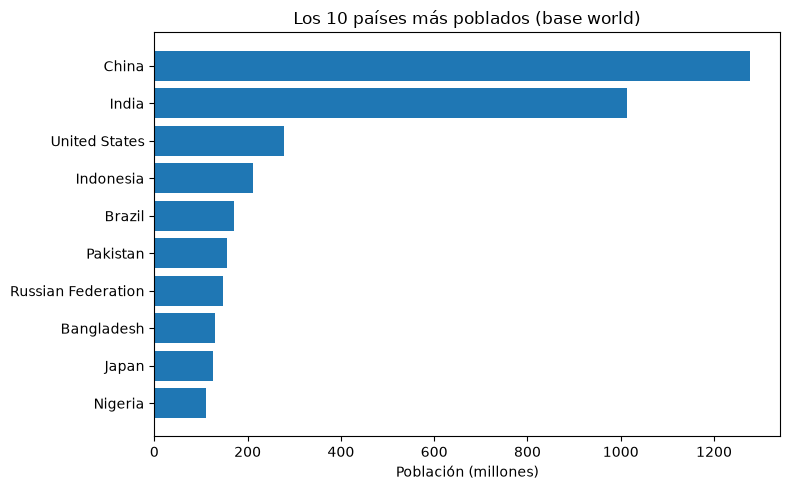

In [29]:
import matplotlib.pyplot as plt

top = df.nlargest(10, "Population").sort_values("Population")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["Name"], top["Population"] / 1e6)
ax.set_xlabel("Población (millones)")
ax.set_title("Los 10 países más poblados (base world)")
plt.tight_layout()
plt.show()

html
<style>
    .yellow {
        background-color: #550000;
    }
</style>
<div class="yellow">
<h1> 11. Cerrar la conexión </h1>
Siempre cerramos cursor y conexión al terminar: el servidor tiene un número limitado de conexiones simultáneas.
</div>


In [32]:
cursor.close()
conn.close()
engine.dispose()
print("Conexión cerrada")

Conexión cerrada


html
<style>
    .yellow {
        background-color: #aa5500;
    }
</style>
<div class="yellow">
<h1> 12. Manejo de errores </h1>
En un programa real, una consulta puede fallar por muchos motivos: el servidor está apagado, la tabla no existe, hay un error de sintaxis, una columna está mal escrita…

Todos estos errores llegan a Python como excepciones de tipo `mysql.connector.Error`. Cada una trae:
- `err.errno`: el código numérico de MySQL (por ejemplo `1146` = la tabla no existe).
- `err.msg`: el mensaje del servidor.

Vamos a armar una función que **abre la conexión, ejecuta la consulta y siempre cierra todo**, pase lo que pase. Para eso usamos `with`: al salir del bloque (normalmente o por un error), Python cierra el cursor y la conexión automáticamente.
</div>



In [38]:
import mysql.connector
from mysql.connector import errorcode


def ejecutar_consulta(sql, params=None):
    """Ejecuta un SELECT y devuelve (columnas, filas). Si algo falla, muestra el error y devuelve (None, None)."""
    
    try:
        with mysql.connector.connect(host=HOST, port=PORT, user=USER, password=PASSWORD, database=DATABASE) as conn:
            with conn.cursor() as cur:
                cur.execute(sql, params)
                columnas = [d[0] for d in cur.description]
                return columnas, cur.fetchall()

    except mysql.connector.Error as err:
        if err.errno == errorcode.ER_ACCESS_DENIED_ERROR:       # 1045
            print("Error: usuario o contraseña incorrectos.")
        elif err.errno == errorcode.ER_BAD_DB_ERROR:            # 1049
            print(f"Error: la base '{DATABASE}' no existe.")
        elif err.errno == errorcode.ER_NO_SUCH_TABLE:           # 1146
            print("Error: la tabla no existe ->", err.msg)
        elif err.errno == errorcode.ER_BAD_FIELD_ERROR:         # 1054
            print("Error: columna desconocida ->", err.msg)
        elif err.errno == errorcode.ER_PARSE_ERROR:             # 1064
            print("Error de sintaxis SQL ->", err.msg)
        elif err.errno == errorcode.CR_CONN_HOST_ERROR:         # 2003
            print("Error: no se pudo conectar. ¿Está iniciado el servidor MySQL?")
        else:
            print(f"Error MySQL {err.errno}: {err.msg}")
        return None, None

sql="ERROR"
ejecutar_consulta(sql)
sql="SELECT * FROM estudiantes LIMIT 5"
ejecutar_consulta(sql)
sql="SELECT * FROM city LIMIT 5"
ejecutar_consulta(sql)

Error de sintaxis SQL -> You have an error in your SQL syntax; check the manual that corresponds to your MySQL server version for the right syntax to use near 'ERROR' at line 1
Error: la tabla no existe -> Table 'taller_db.estudiantes' doesn't exist


(['ID', 'Name', 'CountryCode', 'District', 'Population'],
 [(1, 'Kabul', 'AFG', 'Kabol', 1780000),
  (2, 'Qandahar', 'AFG', 'Qandahar', 237500),
  (3, 'Herat', 'AFG', 'Herat', 186800),
  (4, 'Mazar-e-Sharif', 'AFG', 'Balkh', 127800),
  (5, 'Amsterdam', 'NLD', 'Noord-Holland', 731200)])

In [35]:
def mostrar(columnas, filas):
    """Imprime el resultado como tabla (si la consulta funcionó)."""
    if filas is None:
        return
    print(" | ".join(columnas))
    for fila in filas:
        print(" | ".join(str(v) for v in fila))
    print(f"({len(filas)} filas)")

### Consultas que funcionan

In [36]:
# Las 5 ciudades más pobladas
mostrar(*ejecutar_consulta("""
    SELECT Name, CountryCode, Population
    FROM city
    ORDER BY Population DESC
    LIMIT 5
"""))

Name | CountryCode | Population
Mumbai (Bombay) | IND | 10500000
Seoul | KOR | 9981619
São Paulo | BRA | 9968485
Shanghai | CHN | 9696300
Jakarta | IDN | 9604900
(5 filas)


In [39]:
# Ciudades de un país, con parámetros
mostrar(*ejecutar_consulta(
    "SELECT Name, District, Population FROM city WHERE CountryCode = %s ORDER BY Population DESC LIMIT %s",
    ("ARG", 5),
))

Name | District | Population
Buenos Aires | Distrito Federal | 2982146
La Matanza | Buenos Aires | 1266461
Córdoba | Córdoba | 1157507
Rosario | Santa Fé | 907718
Lomas de Zamora | Buenos Aires | 622013
(5 filas)


### Consultas con errores (a propósito)
Cada una falla por un motivo distinto. Fíjense que el programa **no se interrumpe**: la función atrapa el error y sigue.

In [40]:
# 1) La tabla no existe (ciudad en lugar de city)
mostrar(*ejecutar_consulta("SELECT * FROM ciudad LIMIT 5"))

Error: la tabla no existe -> Table 'taller_db.ciudad' doesn't exist


In [41]:
# 2) Columna mal escrita (Poblacion en lugar de Population)
mostrar(*ejecutar_consulta("SELECT Name, Poblacion FROM city LIMIT 5"))

Error: columna desconocida -> Unknown column 'Poblacion' in 'field list'


In [42]:
# 3) Error de sintaxis (coma de más antes de FROM)
mostrar(*ejecutar_consulta("SELECT Name, FROM city WHERE Population > 1000000"))

Error de sintaxis SQL -> You have an error in your SQL syntax; check the manual that corresponds to your MySQL server version for the right syntax to use near 'FROM city WHERE Population > 1000000' at line 1


In [43]:
# 4) JOIN con un alias mal usado (co.Nombre no existe)
mostrar(*ejecutar_consulta("""
    SELECT ci.Name, co.Nombre
    FROM city ci JOIN country co ON ci.CountryCode = co.Code
    WHERE co.Continent = %s
    LIMIT 5
""", ("South America",)))

Error: columna desconocida -> Unknown column 'co.Nombre' in 'field list'


html
<style>
    .yellow {
        background-color: #000055;
    }
</style>
<div class="yellow">
<h1> 13. Ejemplo completo: leer, calcular, crear una tabla y guardar los resultados </h1>
Vamos a responder: **¿qué porcentaje de la población de cada país vive en las ciudades registradas en la base?**

Pasos:
1. **Leer** de MySQL la población de cada país y la suma de la población de sus ciudades.
2. **Calcular** en Python (con pandas) el porcentaje.
3. **Crear** una tabla nueva `resumen_urbanizacion`.
4. **Insertar** los resultados y confirmar con `commit()`.
5. **Verificar** consultando la tabla nueva.

Todo dentro de un `try/except`: si algo falla durante la carga, hacemos `rollback()` para no dejar la tabla a medio llenar.
</div>


### Paso 1: leer los datos

In [44]:
import pandas as pd

columnas, filas = ejecutar_consulta("""
    SELECT co.Code, co.Name, co.Continent, co.Population,
           COUNT(*)           AS cantidad_ciudades,
           SUM(ci.Population) AS poblacion_ciudades
    FROM country co
    JOIN city ci ON ci.CountryCode = co.Code
    GROUP BY co.Code, co.Name, co.Continent, co.Population
""")

datos = pd.DataFrame(filas, columns=columnas)
datos.head()

,Code,Name,Continent,Population,cantidad_ciudades,poblacion_ciudades
0,ABW,Aruba,North America,103000,1,29034
1,AFG,Afghanistan,Asia,22720000,4,2332100
2,AGO,Angola,Africa,12878000,5,2561600
3,AIA,Anguilla,North America,8000,2,1556
4,ALB,Albania,Europe,3401200,1,270000


### Paso 2: calcular

In [46]:
poblacion_total=datos["poblacion_ciudades"].sum()
datos["pct_en_ciudades"] = (datos["poblacion_ciudades"] / poblacion_total * 100).round(2)

datos.sort_values("pct_en_ciudades", ascending=False).head(10)

,Code,Name,Continent,Population,cantidad_ciudades,poblacion_ciudades,pct_en_ciudades
38,CHN,China,Asia,1277558000,363,175953614,12.31
95,IND,India,Asia,1013662000,341,123298526,8.62
28,BRA,Brazil,South America,170115000,250,85876862,6.01
216,USA,United States,North America,278357000,274,78625774,5.50
104,JPN,Japan,Asia,126714000,248,77965107,5.45
176,RUS,Russian Federation,Europe,146934000,189,69150700,4.84
130,MEX,Mexico,North America,98881000,173,59752521,4.18
111,KOR,South Korea,Asia,46844000,70,38999893,2.73
94,IDN,Indonesia,Asia,212107000,85,37485695,2.62
159,PAK,Pakistan,Asia,156483000,59,31546745,2.21


### Pasos 3 y 4: crear la tabla e insertar
- `DROP TABLE IF EXISTS` permite volver a ejecutar la celda sin error de "la tabla ya existe".
- `executemany()` inserta todas las filas con una sola instrucción.
- Los valores de pandas son tipos de numpy (`numpy.int64`), que el conector no acepta: los convertimos a `int`/`float`/`str` de Python.
- MySQL, `CREATE TABLE` y `DROP TABLE` hacen un commit implícito. El `rollback()` solo deshace los `INSERT`.

In [47]:
columnas_tabla = ["Code", "Name", "Continent", "Population", "cantidad_ciudades", "poblacion_ciudades", "pct_en_ciudades"]
filas_a_insertar = datos[columnas_tabla].astype(object).values.tolist()

conn = None
try:
    conn = mysql.connector.connect(host=HOST, port=PORT, user=USER, password=PASSWORD, database=DATABASE)
    cur = conn.cursor()

    #cur.execute("DROP TABLE IF EXISTS resumen_urbanizacion")
    cur.execute("""
        CREATE TABLE resumen_urbanizacion (
            Code               CHAR(3)      PRIMARY KEY,
            Name               VARCHAR(52)  NOT NULL,
            Continent          VARCHAR(20),
            Population         INT,
            cantidad_ciudades  INT,
            poblacion_ciudades INT,
            pct_en_ciudades    DECIMAL(6,2),
            FOREIGN KEY (Code) REFERENCES country(Code)
        )
    """)

    cur.executemany("""
        INSERT INTO resumen_urbanizacion
            (Code, Name, Continent, Population, cantidad_ciudades, poblacion_ciudades, pct_en_ciudades)
        VALUES (%s, %s, %s, %s, %s, %s, %s)
    """, filas_a_insertar)

    conn.commit()
    print(f"Se insertaron {cur.rowcount} filas en resumen_urbanizacion")

except mysql.connector.Error as err:
    print(f"Error MySQL {err.errno}: {err.msg}")
    if conn is not None and conn.is_connected():
        conn.rollback()
        print("Se deshicieron los cambios (rollback)")

finally:
    if conn is not None and conn.is_connected():
        cur.close()
        conn.close()

Se insertaron 232 filas en resumen_urbanizacion


### Paso 5: verificar

In [48]:
sql_filas_insertadas="""
    SELECT Name, Continent, cantidad_ciudades, pct_en_ciudades
    FROM resumen_urbanizacion
    WHERE Continent = %s
    ORDER BY pct_en_ciudades DESC
"""

mostrar(*ejecutar_consulta(sql_filas_insertadas, ("South America",)))

Name | Continent | cantidad_ciudades | pct_en_ciudades
Brazil | South America | 250 | 6.01
Colombia | South America | 38 | 1.42
Argentina | South America | 57 | 1.40
Venezuela | South America | 41 | 0.86
Peru | South America | 22 | 0.85
Chile | South America | 29 | 0.68
Ecuador | South America | 15 | 0.40
Bolivia | South America | 8 | 0.24
Uruguay | South America | 1 | 0.09
Paraguay | South America | 5 | 0.07
Guyana | South America | 1 | 0.02
Suriname | South America | 1 | 0.01
Falkland Islands | South America | 1 | 0.00
French Guiana | South America | 1 | 0.00
(14 filas)


La tabla nueva queda guardada en la base `world`: la pueden ver desde Workbench (refrescar la lista de tablas) y consultarla como cualquier otra.

Para borrarla:
```sql
DROP TABLE resumen_urbanizacion;
```